In [1]:

import pandas as pd

# Load the uploaded dataset
df = pd.read_csv('/content/crop.csv')

# Display the first five rows
print("First five rows:")
display(df.head())


First five rows:


,State_Name,District_Name,Crop_Year,Season,Crop,Area,Production
0,Andaman and Nicobar Islands,NICOBARS,2000.0,Kharif,Arecanut,1254.0,2000.0
1,Andaman and Nicobar Islands,NICOBARS,2000.0,Kharif,Other Kharif pulses,2.0,1.0
2,Andaman and Nicobar Islands,NICOBARS,2000.0,Kharif,Rice,102.0,321.0
3,Andaman and Nicobar Islands,NICOBARS,2000.0,Whole Year,Banana,176.0,641.0
4,Andaman and Nicobar Islands,NICOBARS,2000.0,Whole Year,Cashewnut,720.0,165.0


In [2]:

# Check dataset size
print("Number of rows and columns:", df.shape)

# Check column names
print("\nColumn names:")
print(df.columns.tolist())

# Check data types
print("\nData types:")
print(df.dtypes)

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Get summary statistics
print("\nSummary statistics:")
display(df.describe(include='all').T)


Number of rows and columns: (169841, 7)

Column names:
['State_Name', 'District_Name', 'Crop_Year', 'Season', 'Crop', 'Area', 'Production']

Data types:
State_Name        object
District_Name     object
Crop_Year        float64
Season            object
Crop              object
Area             float64
Production       float64
dtype: object

Missing values:
State_Name          0
District_Name       1
Crop_Year           1
Season              1
Crop                1
Area                1
Production       2927
dtype: int64

Summary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
State_Name,169841,26,Madhya Pradesh,22943,NaN,NaN,NaN,NaN,NaN,NaN,NaN
District_Name,169840,471,BIJAPUR,945,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Crop_Year,169840.0,NaN,NaN,NaN,2005.68279,4.922558,1997.0,2002.0,2006.0,2010.0,2015.0
Season,169840,6,Kharif,65306,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Crop,169840,111,Rice,11171,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Area,169840.0,NaN,NaN,NaN,11470.685894,38035.497417,0.04,93.0,600.0,4207.25,1020181.0
Production,166914.0,NaN,NaN,NaN,741846.910291,19675874.219415,0.0,100.0,728.55,6623.75,1125000000.0


In [3]:

# Identify numeric columns
numeric_cols = df.select_dtypes(include='number').columns.tolist()

# Identify categorical columns
categorical_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

print("Numeric columns:", numeric_cols)
print("\nCategorical columns:", categorical_cols)


Numeric columns: ['Crop_Year', 'Area', 'Production']

Categorical columns: ['State_Name', 'District_Name', 'Season', 'Crop']


In [4]:

# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check missing values
print("\nMissing values per column:")
print(df.isnull().sum())

# Check numeric summary
print("\nNumeric summary:")
display(df.describe().T)

# Check unique values in categorical columns
for col in categorical_cols:
    print(f"\n{col}: {df[col].nunique()} unique values")


Duplicate rows: 0

Missing values per column:
State_Name          0
District_Name       1
Crop_Year           1
Season              1
Crop                1
Area                1
Production       2927
dtype: int64

Numeric summary:


,count,mean,std,min,25%,50%,75%,max
Crop_Year,169840.0,2005.682790,4.922558e+00,1997.00,2002.0,2006.00,2010.00,2.015000e+03
Area,169840.0,11470.685894,3.803550e+04,0.04,93.0,600.00,4207.25,1.020181e+06
Production,166914.0,741846.910291,1.967587e+07,0.00,100.0,728.55,6623.75,1.125000e+09



State_Name: 26 unique values

District_Name: 471 unique values

Season: 6 unique values

Crop: 111 unique values


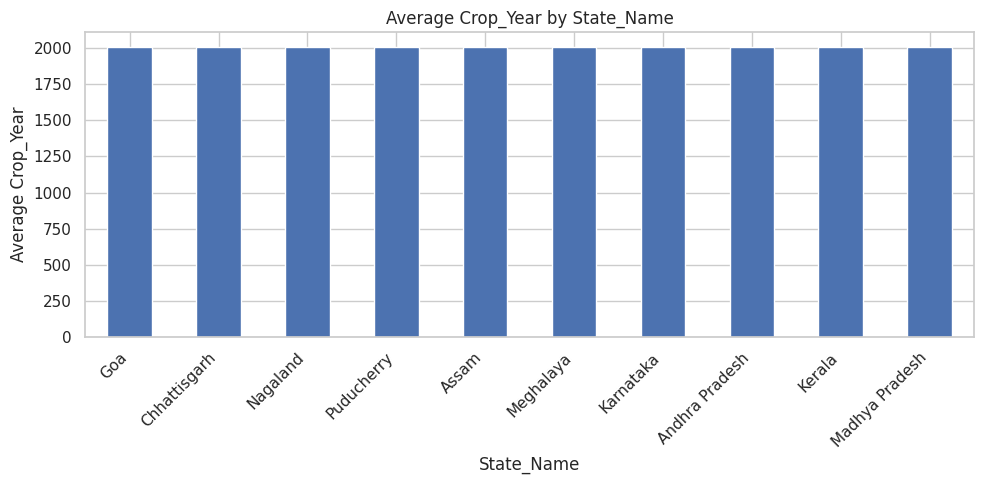

In [19]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Select the first categorical and numeric columns
if categorical_cols and numeric_cols:
    category = categorical_cols[0]
    metric = numeric_cols[0]

    chart_data = (
        df.groupby(category, dropna=True)[metric]
        .mean()
        .dropna()
        .sort_values(ascending=False)
        .head(10)
    )

    chart_data.plot(kind="bar", figsize=(10, 5))
    plt.title(f"Average {metric} by {category}")
    plt.xlabel(category)
    plt.ylabel(f"Average {metric}")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.savefig("chart1_bar.png", dpi=300, bbox_inches="tight")
    plt.show()
else:
    print("A categorical column and a numeric column are needed.")


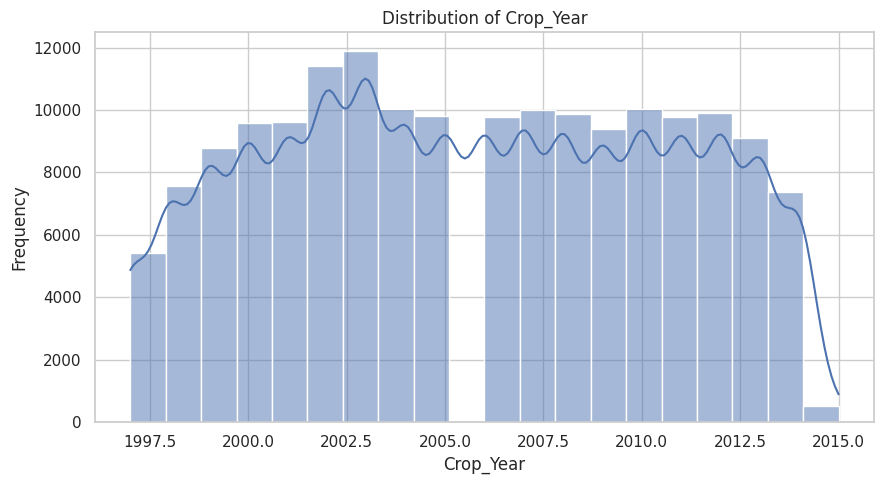

In [20]:

if numeric_cols:
    metric = numeric_cols[0]
    values = df[metric].dropna()

    plt.figure(figsize=(9, 5))
    sns.histplot(values, bins=20, kde=True)
    plt.title(f"Distribution of {metric}")
    plt.xlabel(metric)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.savefig("chart2_histogram.png", dpi=300, bbox_inches="tight")
    plt.show()
else:
    print("No numeric columns are available.")


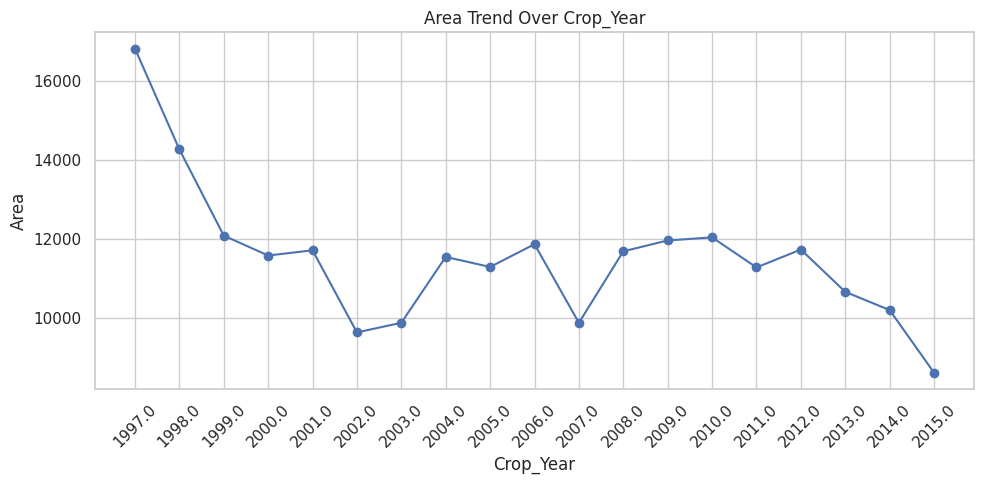

In [21]:
# Find a likely time column
time_cols = [
    col for col in df.columns
    if any(word in col.lower()
           for word in ["year", "date", "time"])
]

if time_cols and numeric_cols:
    time_col = time_cols[0]
    # Ensure we choose a metric that is different from the time column
    remaining_metrics = [col for col in numeric_cols if col != time_col]
    metric = remaining_metrics[0] if remaining_metrics else numeric_cols[0]

    line_data = df[[time_col, metric]].dropna()

    line_data = (
        line_data.groupby(time_col)[metric]
        .mean()
        .sort_index()
    )

    plt.figure(figsize=(10, 5))
    plt.plot(line_data.index.astype(str),
             line_data.values, marker="o")
    plt.title(f"{metric} Trend Over {time_col}")
    plt.xlabel(time_col)
    plt.ylabel(metric)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.savefig("chart3_line.png", dpi=300, bbox_inches="tight")
    plt.show()
else:
    print("No suitable time column found. Check your dataset columns.")

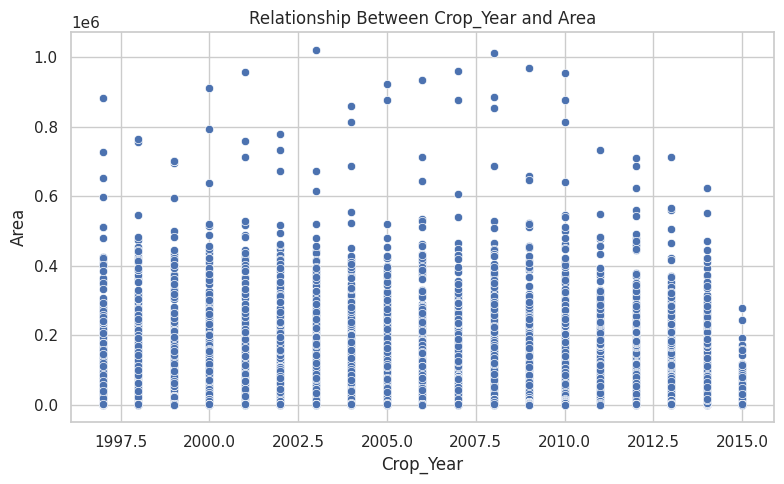

In [22]:

if len(numeric_cols) >= 2:
    x_col = numeric_cols[0]
    y_col = numeric_cols[1]

    plt.figure(figsize=(8, 5))
    sns.scatterplot(data=df, x=x_col, y=y_col)
    plt.title(f"Relationship Between {x_col} and {y_col}")
    plt.xlabel(x_col)
    plt.ylabel(y_col)
    plt.tight_layout()
    plt.savefig("chart4_Scatter.png", dpi=300, bbox_inches="tight")
    plt.show()
else:
    print("At least two numeric columns are needed.")


In [14]:

summary_table = df[numeric_cols].agg(
    ["count", "mean", "median", "min", "max", "std"]
).T

summary_table.columns = [
    "Count", "Mean", "Median", "Minimum", "Maximum", "Std. Deviation"
]

display(summary_table.round(2))


,Count,Mean,Median,Minimum,Maximum,Std. Deviation
Crop_Year,169840.0,2005.68,2006.00,1997.00,2.015000e+03,4.92
Area,169840.0,11470.69,600.00,0.04,1.020181e+06,38035.50
Production,166914.0,741846.91,728.55,0.00,1.125000e+09,19675874.22


In [15]:

if categorical_cols and numeric_cols:
    category = categorical_cols[0]
    metric = numeric_cols[0]

    averages = df.groupby(category)[metric].mean().dropna()

    print("Category with highest average:")
    print(averages.idxmax(), ":", round(averages.max(), 2))

    print("\nCategory with lowest average:")
    print(averages.idxmin(), ":", round(averages.min(), 2))
else:
    print("Check whether suitable categorical and numeric columns exist.")


Category with highest average:
Goa : 2009.11

Category with lowest average:
Manipur : 2002.18


In [23]:
summary_table.to_csv("summary_table.csv")
print("Summary table saved successfully!")

Summary table saved successfully!


In [24]:
print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())
print("Missing values:")
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

Dataset shape: (169841, 7)
Column names: ['State_Name', 'District_Name', 'Crop_Year', 'Season', 'Crop', 'Area', 'Production']
Missing values:
State_Name          0
District_Name       1
Crop_Year           1
Season              1
Crop                1
Area                1
Production       2927
dtype: int64
Duplicate rows: 0
